In [30]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import kagglehub
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")
import os 
os.listdir(path)

['amz_uk_price_prediction_dataset.csv']

In [3]:
df = pd.read_csv(os.path.join(path, "amz_uk_price_prediction_dataset.csv"))

print(df.head(),df.info(), df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6  

In [4]:
cat=df.select_dtypes(exclude="number")
num=df.select_dtypes(include="number")

In [5]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

---

In [6]:
crosstab_1=pd.crosstab(cat["category"],cat["isBestSeller"]).sort_values(by=True,ascending=False)
crosstab_1.info()

count_100=(crosstab_1[True]>100).sum()
# There are 19 categories where being a best seller happens in more than 100 cases.
count_ls100=(crosstab_1[True]<=100).sum()
# There are 277 categories where being a best seller happens in more than 100 cases.
count_Nan=(crosstab_1[True]).isnull().sum()
print(count_100)
print(count_ls100)
print(count_Nan)

crosstab_1_100=crosstab_1[crosstab_1[True]>100]
print(crosstab_1_100)


<class 'pandas.DataFrame'>
Index: 296 entries, Grocery to eBook Readers & Accessories
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   False   296 non-null    int64
 1   True    296 non-null    int64
dtypes: int64(2)
memory usage: 6.9+ KB
19
277
0
isBestSeller                        False  True 
category                                        
Grocery                              9008    556
Health & Personal Care               9017    552
Baby                                14709    341
Sports & Outdoors                  835935    330
Power & Hand Tools                   8353    306
Beauty                              19010    302
Pet Supplies                         9152    285
Arts & Crafts                        9319    230
Women                               17559    213
Men                                 17248    169
PC & Video Games                     6008    157
Storage & Organisation               9414    155
Hardware

In [7]:
proportion_bestsellers = pd.crosstab(
    cat["category"],
    cat["isBestSeller"],
    normalize="index"
)[True].sort_values(ascending=False)

# the following table expresses the proportion of the best sellers regarding the total number of books sold.

print(proportion_bestsellers.head(50))


category
Grocery                              0.058135
Smart Home Security & Lighting       0.057692
Health & Personal Care               0.057686
Mobile Phone Accessories             0.042471
Power & Hand Tools                   0.035339
Billiard, Snooker & Pool             0.032129
Pet Supplies                         0.030200
Home Brewing & Wine Making           0.028455
Mirrors                              0.028000
Wind Instruments                     0.028000
Professional Medical Supplies        0.027344
PC & Video Games                     0.025466
Bakeware                             0.025105
Material Handling Products           0.025000
Bedding Accessories                  0.024390
Tableware                            0.024096
Arts & Crafts                        0.024086
Baby                                 0.022658
Lighting                             0.022556
Window Treatments                    0.020921
Kitchen Linen                        0.020661
Luxury Food & Drink      

In [8]:
from scipy.stats import chi2_contingency

In [9]:
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_1)
float(chi2_pvalue)
print(chi2_pvalue)

0.0


In [10]:
from scipy.stats.contingency import association

In [11]:
association(crosstab_1, method='cramer')

# It has a weak strength association.

0.1222829439760564

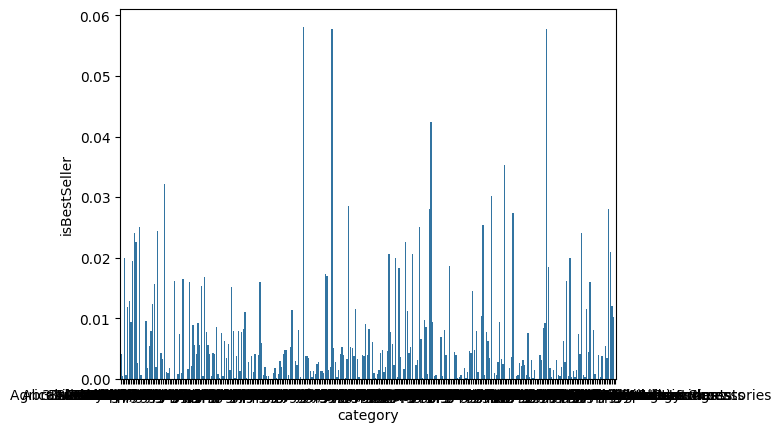

In [12]:
prop = (cat.groupby("category")["isBestSeller"].mean().reset_index())
sns.barplot(data=prop,x="category",y="isBestSeller")
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

---

In [ ]:
df_clean = df.copy()

q1 = df_clean["price"].quantile(0.25)
q3 = df_clean["price"].quantile(0.75)
iqr = q3 - q1

print(iqr)

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print(lower,upper)


df_no_outliers = df_clean[df_clean["price"].between(lower, upper)].copy()

top20_cats = df_no_outliers["category"].value_counts().head(20).index
top10_cats = df_no_outliers["category"].value_counts().head(10).index


36.0
-44.01 99.99000000000001


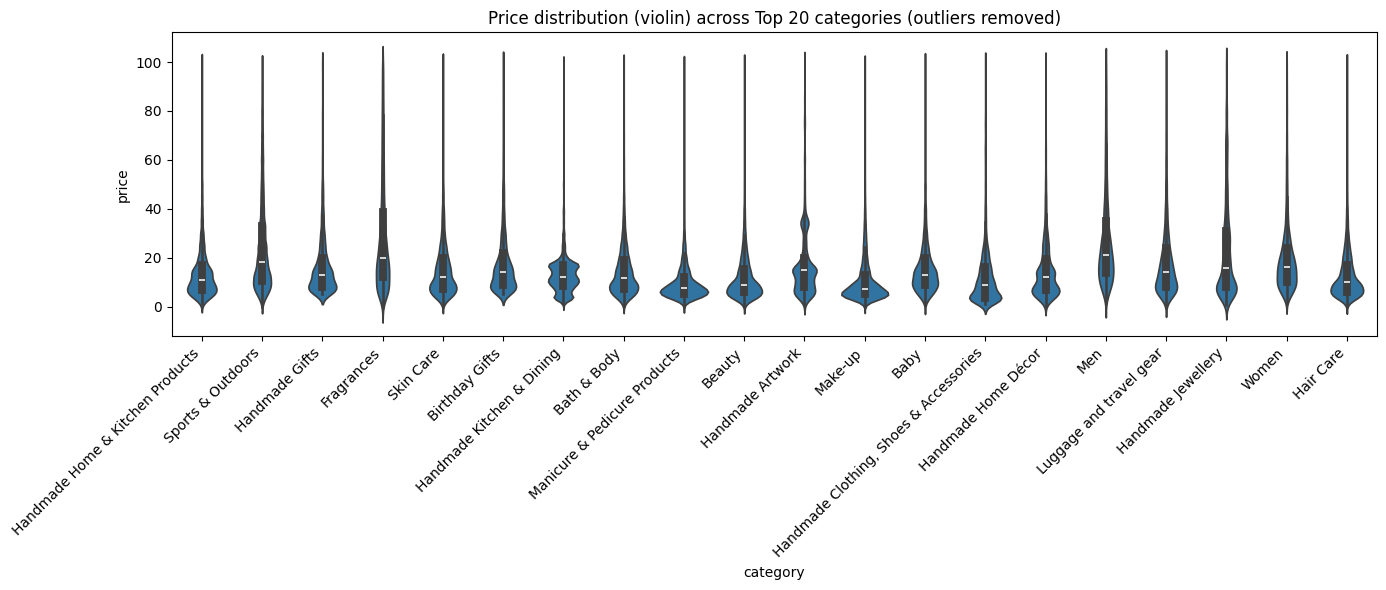

In [14]:
plt.figure(figsize=(14, 6))
sns.violinplot(
    data=df_no_outliers[df_no_outliers["category"].isin(top20_cats)],
    x="category",
    y="price"
)
plt.xticks(rotation=45, ha="right")
plt.title("Price distribution (violin) across Top 20 categories (outliers removed)")
plt.tight_layout()
plt.show()

In [15]:
median_price_by_cat = df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False)
print("Category with highest median price (no top-category filter):", median_price_by_cat.index[0])
print(median_price_by_cat.head(10))

Category with highest median price (no top-category filter): Desktop PCs
category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64


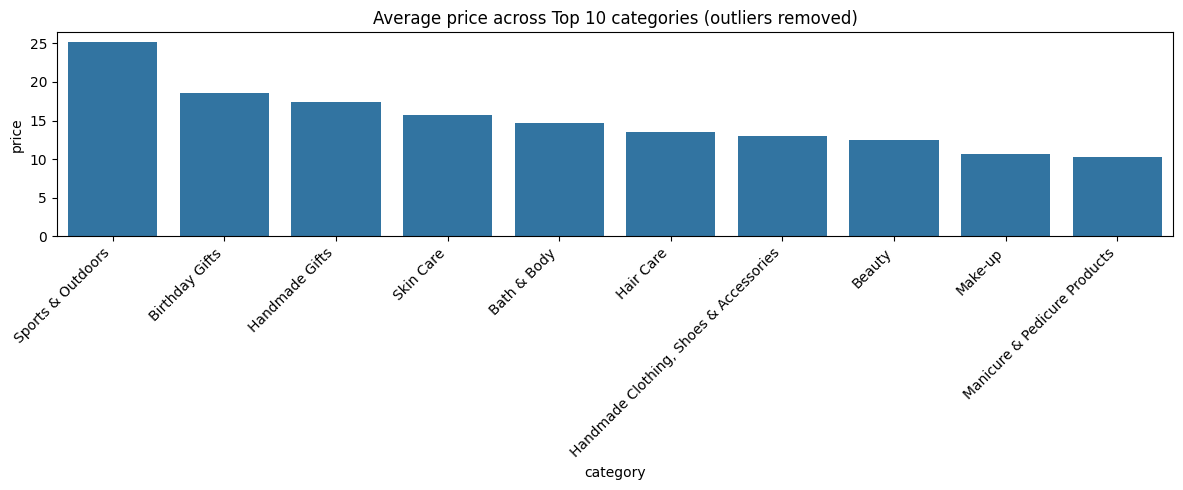

In [16]:
avg_price_top10 = (
    df_no_outliers[df_no_outliers["category"].isin(top10_cats)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.barplot(data=avg_price_top10, x="category", y="price")
plt.xticks(rotation=45, ha="right")
plt.title("Average price across Top 10 categories (outliers removed)")
plt.tight_layout()
plt.show()

In [17]:
mean_price_by_cat = df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False)
print("Category with highest average price (no top-category filter):", mean_price_by_cat.index[0])
print(mean_price_by_cat.head(10))


Category with highest average price (no top-category filter): Motherboards
category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64


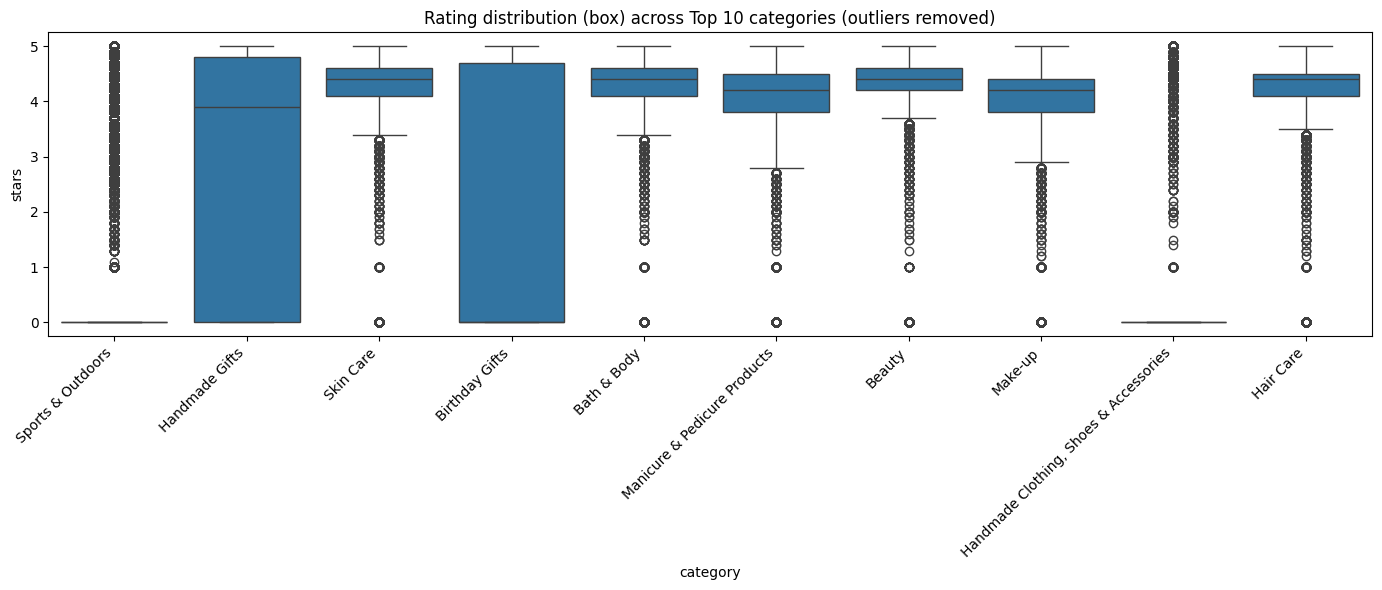

In [18]:
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df_no_outliers[df_no_outliers["category"].isin(top10_cats)],
    x="category",
    y="stars"
)
plt.xticks(rotation=45, ha="right")
plt.title("Rating distribution (box) across Top 10 categories (outliers removed)")
plt.tight_layout()
plt.show()


In [19]:
median_rating_by_cat = df_no_outliers.groupby("category")["stars"].median().sort_values(ascending=False)
print("Category with highest median rating (no top-category filter):", median_rating_by_cat.index[0])
print(median_rating_by_cat.head(10))

Category with highest median rating (no top-category filter): Computer Memory
category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64


### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?


In [20]:
corr = df["price"].corr(df["stars"])
print("Correlation between price and stars:", corr)

Correlation between price and stars: -0.12490673262148386


In [21]:
corr_spearman = df["price"].corr(df["stars"], method="spearman")
print("Spearman correlation:", corr_spearman)

Spearman correlation: -0.13316425462433876


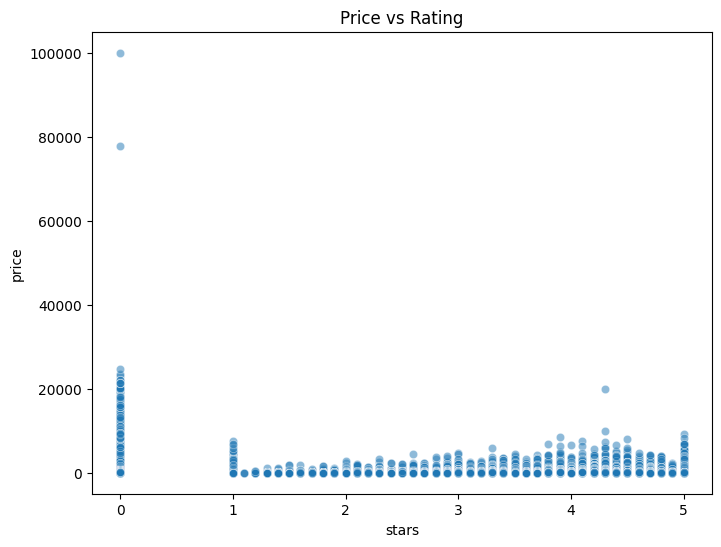

In [22]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x="stars", y="price", alpha=0.5)
plt.title("Price vs Rating")
plt.show()

<Axes: xlabel='stars', ylabel='price'>

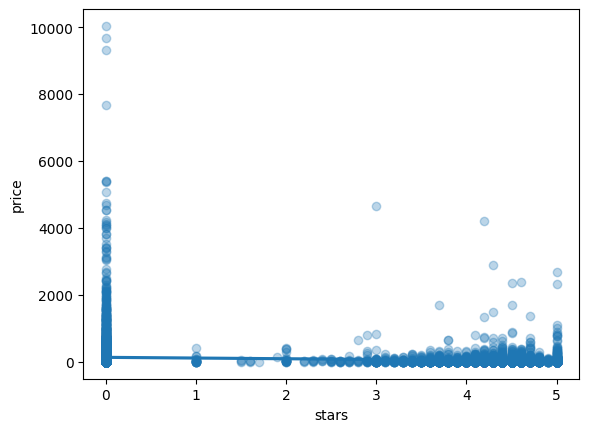

In [23]:
sample_df = df.sample(10000, random_state=42)

sns.regplot(
    data=sample_df,
    x="stars",
    y="price",
    scatter_kws={"alpha": 0.3},
    ci=None
)

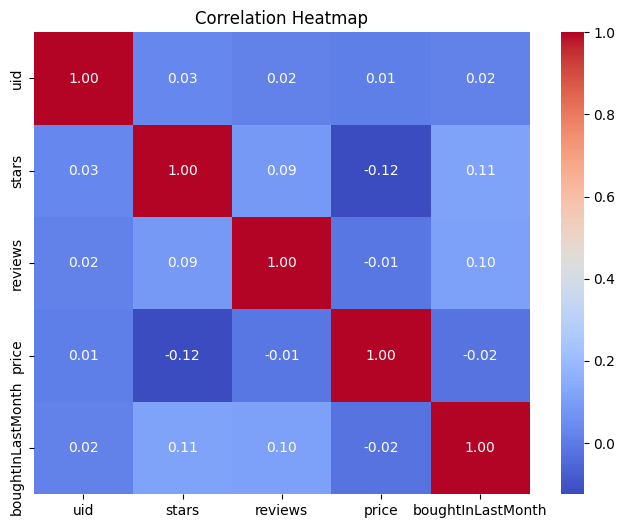

In [27]:
plt.figure(figsize=(8,6))
numeric_df = df.select_dtypes(include=np.number)

corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

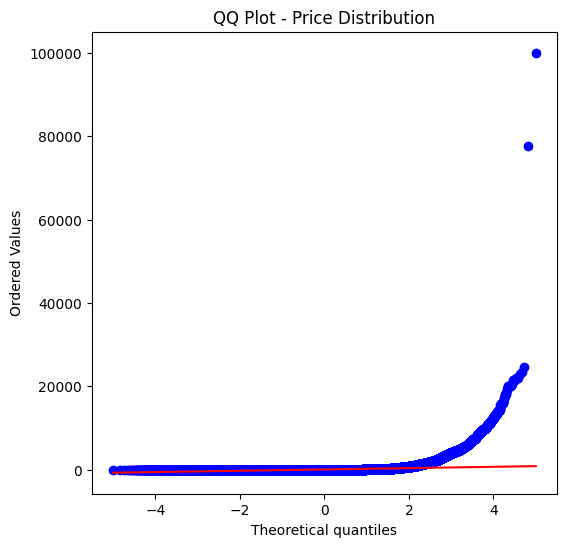

In [31]:
plt.figure(figsize=(6,6))
stats.probplot(df["price"], dist="norm", plot=plt)
plt.title("QQ Plot - Price Distribution")
plt.show()

In [32]:
corr_full = df["price"].corr(df["stars"])
corr_clean = df_no_outliers["price"].corr(df_no_outliers["stars"])

print("Correlation WITH outliers:", corr_full)
print("Correlation WITHOUT outliers:", corr_clean)

Correlation WITH outliers: -0.12490673262148386
Correlation WITHOUT outliers: -0.07767299878181444
